# Etapa 2 — Filtrado Colaborativo Neuronal (NCF)

Implementamos una versión simplificada de **NeuMF** (Neural Collaborative Filtering, He et al. 2017): combina una rama de *Generalized Matrix Factorization* (producto elemento a elemento de embeddings) con una rama *MLP* (concatenación de embeddings + capas densas), y fusiona ambas para predecir el rating.

Usamos el mismo `test_size` y `random_state` que en la Etapa 1 para que la comparación final entre modelos sea justa, y reutilizamos la misma función de `precision_recall_at_k` de ese notebook.

**Antes de correr:** recomendable activar GPU en el entorno de ejecución

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/tesis-recsys'
DATA_DIR = f'{PROJECT_DIR}/data'

Mounted at /content/drive


In [ ]:
import torch
print('PyTorch version:', torch.__version__)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PyTorch version: 2.11.0+cu128
Device: cuda


## 2. Carga de datos y preparación

Reutilizamos el mismo `ratings.csv` descargado en la Etapa 1. A diferencia de Surprise, PyTorch necesita índices enteros contiguos (0, 1, 2, ...) para las capas de embedding, así que mapeamos los `userId`/`movieId` originales a índices propios.

In [ ]:
import pandas as pd

ratings = pd.read_csv(f'{DATA_DIR}/ml-latest-small/ratings.csv')

user_ids = ratings['userId'].unique()
item_ids = ratings['movieId'].unique()

user2idx = {u: i for i, u in enumerate(user_ids)}
item2idx = {m: i for i, m in enumerate(item_ids)}

ratings['user_idx'] = ratings['userId'].map(user2idx)
ratings['item_idx'] = ratings['movieId'].map(item2idx)

n_users = len(user2idx)
n_items = len(item2idx)
print(f'Usuarios: {n_users}, Ítems: {n_items}')

Usuarios: 610, Ítems: 9724


In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=42)
print(f'Train: {len(train_df)} | Test: {len(test_df)}')

Train: 80668 | Test: 20168


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

class RatingsDataset(Dataset):
    def __init__(self, df):
        self.users = torch.tensor(df['user_idx'].values, dtype=torch.long)
        self.items = torch.tensor(df['item_idx'].values, dtype=torch.long)
        self.ratings = torch.tensor(df['rating'].values, dtype=torch.float32)

    def __len__(self):
        return len(self.ratings)

    def __getitem__(self, idx):
        return self.users[idx], self.items[idx], self.ratings[idx]

BATCH_SIZE = 256
train_loader = DataLoader(RatingsDataset(train_df), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(RatingsDataset(test_df), batch_size=BATCH_SIZE, shuffle=False)

## 3. Modelo: NeuMF simplificado

In [ ]:
import torch.nn as nn

class NeuMF(nn.Module):
    def __init__(self, n_users, n_items, gmf_dim=16, mlp_dim=32, mlp_layers=[64, 32, 16], rating_range=(0.5, 5.0)):
        super().__init__()
        self.rating_min, self.rating_max = rating_range

        # Rama GMF (producto elemento a elemento)
        self.user_emb_gmf = nn.Embedding(n_users, gmf_dim)
        self.item_emb_gmf = nn.Embedding(n_items, gmf_dim)

        # Rama MLP (concatenación + capas densas)
        self.user_emb_mlp = nn.Embedding(n_users, mlp_dim)
        self.item_emb_mlp = nn.Embedding(n_items, mlp_dim)

        mlp_modules = []
        input_size = mlp_dim * 2
        for layer_size in mlp_layers:
            mlp_modules.append(nn.Linear(input_size, layer_size))
            mlp_modules.append(nn.ReLU())
            input_size = layer_size
        self.mlp = nn.Sequential(*mlp_modules)

        # Capa de fusión final: combina la salida de GMF y la del MLP
        self.output_layer = nn.Linear(gmf_dim + mlp_layers[-1], 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, user_idx, item_idx):
        gmf_out = self.user_emb_gmf(user_idx) * self.item_emb_gmf(item_idx)

        mlp_input = torch.cat([self.user_emb_mlp(user_idx), self.item_emb_mlp(item_idx)], dim=-1)
        mlp_out = self.mlp(mlp_input)

        combined = torch.cat([gmf_out, mlp_out], dim=-1)
        out = self.sigmoid(self.output_layer(combined)).squeeze()

        # Escalamos la salida sigmoide (0-1) al rango real de ratings
        return out * (self.rating_max - self.rating_min) + self.rating_min

model = NeuMF(n_users, n_items).to(device)
print(model)

NeuMF(
  (user_emb_gmf): Embedding(610, 16)
  (item_emb_gmf): Embedding(9724, 16)
  (user_emb_mlp): Embedding(610, 32)
  (item_emb_mlp): Embedding(9724, 32)
  (mlp): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
  )
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


## 4. Entrenamiento

In [ ]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

N_EPOCHS = 15
train_losses = []

for epoch in range(1, N_EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    for users_batch, items_batch, ratings_batch in train_loader:
        users_batch, items_batch, ratings_batch = users_batch.to(device), items_batch.to(device), ratings_batch.to(device)

        optimizer.zero_grad()
        preds = model(users_batch, items_batch)
        loss = criterion(preds, ratings_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(ratings_batch)

    epoch_loss /= len(train_loader.dataset)
    train_losses.append(epoch_loss)
    print(f'Epoch {epoch}/{N_EPOCHS} - Train MSE: {epoch_loss:.4f}')

Epoch 1/15 - Train MSE: 1.0943
Epoch 2/15 - Train MSE: 0.9008
Epoch 3/15 - Train MSE: 0.8349
Epoch 4/15 - Train MSE: 0.7883
Epoch 5/15 - Train MSE: 0.7490
Epoch 6/15 - Train MSE: 0.7147
Epoch 7/15 - Train MSE: 0.6842
Epoch 8/15 - Train MSE: 0.6547
Epoch 9/15 - Train MSE: 0.6238
Epoch 10/15 - Train MSE: 0.5937
Epoch 11/15 - Train MSE: 0.5621
Epoch 12/15 - Train MSE: 0.5299
Epoch 13/15 - Train MSE: 0.4985
Epoch 14/15 - Train MSE: 0.4663
Epoch 15/15 - Train MSE: 0.4375


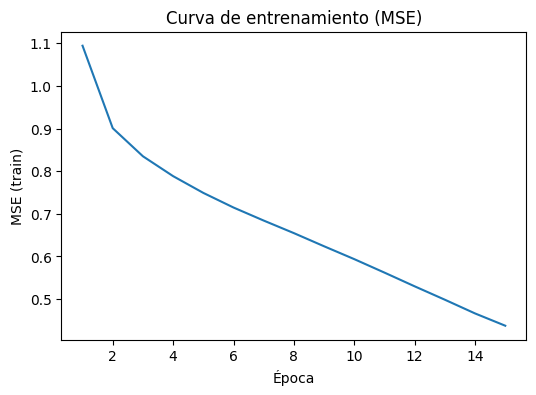

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(range(1, N_EPOCHS + 1), train_losses)
plt.title('Curva de entrenamiento (MSE)')
plt.xlabel('Época')
plt.ylabel('MSE (train)')
plt.show()

## 5. Evaluación: RMSE, MAE, precision@k, recall@k

Armamos las predicciones en el mismo formato `(uid, iid, true_r, est, _)` que usa Surprise, para poder reutilizar textualmente la función `precision_recall_at_k` de la Etapa 1.

In [ ]:
model.eval()
predictions = []

with torch.no_grad():
    for users_batch, items_batch, ratings_batch in test_loader:
        users_device, items_device = users_batch.to(device), items_batch.to(device)
        preds = model(users_device, items_device).cpu().numpy()

        for u, i, true_r, est in zip(users_batch.numpy(), items_batch.numpy(), ratings_batch.numpy(), preds):
            predictions.append((int(u), int(i), float(true_r), float(est), None))

print(f'{len(predictions)} predicciones generadas sobre el set de test.')

20168 predicciones generadas sobre el set de test.


In [ ]:
import numpy as np

def rmse(predictions):
    errors = [(true_r - est) ** 2 for (_, _, true_r, est, _) in predictions]
    return np.sqrt(np.mean(errors))

def mae(predictions):
    errors = [abs(true_r - est) for (_, _, true_r, est, _) in predictions]
    return np.mean(errors)

print('RMSE:', rmse(predictions))
print('MAE:', mae(predictions))

RMSE: 0.9645499936943835
MAE: 0.7388425987599531


In [ ]:
from collections import defaultdict

def precision_recall_at_k(predictions, k=10, threshold=3.5):
    """Misma función que en la Etapa 1 (SVD), reutilizada tal cual para que la comparación sea consistente."""
    user_est_true = defaultdict(list)
    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions, recalls = {}, {}
    for uid, user_ratings in user_est_true.items():
        user_ratings.sort(key=lambda x: x[0], reverse=True)
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])
        n_rel_and_rec_k = sum(
            ((true_r >= threshold) and (est >= threshold))
            for (est, true_r) in user_ratings[:k]
        )
        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0
        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    avg_precision = sum(prec for prec in precisions.values()) / len(precisions)
    avg_recall = sum(rec for rec in recalls.values()) / len(recalls)
    return avg_precision, avg_recall

precision, recall = precision_recall_at_k(predictions, k=10, threshold=3.5)
print(f'Precision@10: {precision:.4f}')
print(f'Recall@10: {recall:.4f}')

Precision@10: 0.7420
Recall@10: 0.5223


## 6. Guardar resultados en la tabla comparativa

In [ ]:
import csv
from datetime import datetime

results_path = f'{PROJECT_DIR}/results/comparativa_modelos.csv'
row = {
    'modelo': 'NCF (NeuMF)',
    'rmse': rmse(predictions),
    'mae': mae(predictions),
    'precision_at_10': precision,
    'recall_at_10': recall,
    'fecha': datetime.now().isoformat(timespec='seconds'),
}

file_exists = os.path.exists(results_path)
with open(results_path, 'a', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=row.keys())
    if not file_exists:
        writer.writeheader()
    writer.writerow(row)

print('Resultado guardado en', results_path)
row

Resultado guardado en /content/drive/MyDrive/tesis-recsys/results/comparativa_modelos.csv


{'modelo': 'NCF (NeuMF)',
 'rmse': np.float64(0.9645499936943835),
 'mae': np.float64(0.7388425987599531),
 'precision_at_10': 0.7419535519125683,
 'recall_at_10': 0.5223323589063418,
 'fecha': '2026-09-27T01:14:26'}